# Days to recovered discharge in Nara

A district nutrition coordinator can use the estimated elapsed duration to plan how long cases that recover may remain on the caseload. The estimate includes programme time for cases that transfer to inpatient care. The coordinator needs separate estimates for other discharge outcomes and for the number of outpatient visits.

Run the notebook with the `summative/.venv` Python kernel after running `uv sync --locked` in `summative/`. Save the original Zenodo CSV in `summative/data/` and run the cohort audit from the README to verify the source checksum.

In [1]:
from pathlib import Path

import pandas as pd
from sklearn.model_selection import train_test_split

data_dir = Path("data") if Path("pyproject.toml").is_file() else Path("../data")
source = pd.read_csv(data_dir / "Mali_Cohort_Study.csv", na_values=["."])

assert source["AnonID"].notna().all() and source["AnonID"].is_unique
source.shape

(27800, 58)

## Select the modeling cohort

Use recovered health-centre cases with a positive recorded duration. Keep only admission fields as candidate predictors. Site is constant after filtering. Record ID is reserved for checking the splits and the inpatient transfer flag is reserved for evaluating errors by subgroup.

All 18 eligible records with oedema lack weight-for-height z-score. Require the seven shared inputs for the main split so that cases with oedema remain represented. Compare seven and eight inputs on the same z-score-complete rows within each split. Confirm z-score availability in the coordinator's workflow before finalizing the input fields.

In [2]:
numeric_features = ["adm_age", "adm_kg", "adm_cm", "adm_muac"]
categorical_features = ["adm_sex", "adm_oedema_YN", "adm_referral"]
shared_features = numeric_features + categorical_features
z_score = "adm_whz06"
target = "recovered_los"

eligible = source.loc[
    source["adm_site"].eq("Health Center")
    & source["cured"].eq(1)
    & source[target].gt(0)
]
cohort = (
    eligible[["AnonID", *shared_features, z_score, target, "transfer_inpatient"]]
    .dropna(subset=shared_features)
    .set_index("AnonID")
    .sort_index()
)
print(f"{len(eligible):,} eligible records, {len(cohort):,} with the shared inputs")
print(f"{cohort[z_score].notna().sum():,} also have a z-score")
print(f"Recorded duration ranges from {cohort[target].min():g} to {cohort[target].max():g} days")

20,484 eligible records, 20,057 with the shared inputs
20,002 also have a z-score
Recorded duration ranges from 10 to 112 days


## Reserve test and retraining rows

The CSV has no admission date, so these are random splits of historical records. Reserve 20% for the shared test set and 10% for the retraining demonstration. The demo batch remains outside preprocessing, tuning, and model selection. Preserve the rare oedema category in each split by stratifying on the admission flag.

In [3]:
seed = 42
train_and_demo, test = train_test_split(
    cohort, test_size=0.20, random_state=seed, stratify=cohort["adm_oedema_YN"]
)
train, retraining_batch = train_test_split(
    train_and_demo,
    test_size=0.125,
    random_state=seed,
    stratify=train_and_demo["adm_oedema_YN"],
)

splits = {"train": train, "test": test, "retraining": retraining_batch}
split_ids = pd.Index([record_id for rows in splits.values() for record_id in rows.index])
assert split_ids.is_unique and len(split_ids) == len(cohort)

pd.DataFrame({
    name: {
        "Rows": len(rows),
        "With z-score": rows[z_score].notna().sum(),
        "Oedema cases": rows["adm_oedema_YN"].eq(1).sum(),
    }
    for name, rows in splits.items()
}).T

,Rows,With z-score,Oedema cases
train,14039,14002,10
test,4012,4001,3
retraining,2006,1999,2


## Explore recovery duration

Each bar groups training cases into a seven-day interval. The held-out test and retraining groups stay separate from this exploration.

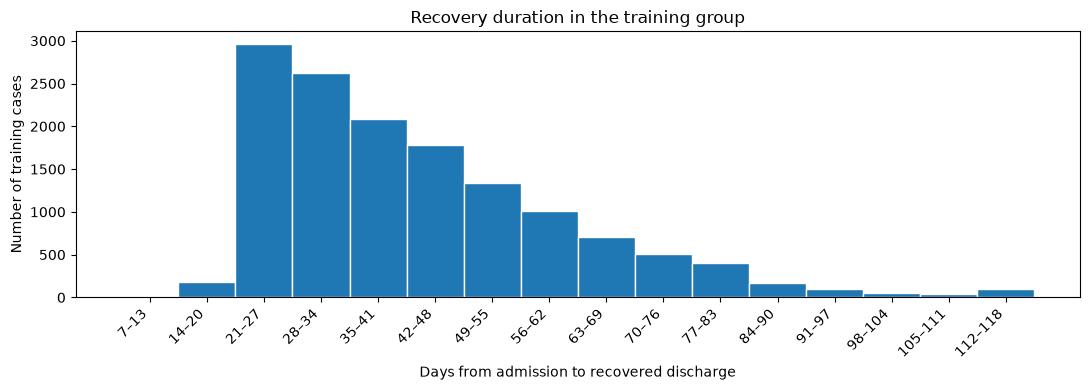

In [5]:
import matplotlib.pyplot as plt

week_starts = list(range(7, 113, 7))
week_labels = [f"{day}–{day + 6}" for day in week_starts]

fig, ax = plt.subplots(figsize=(11, 4))
ax.hist(train[target], bins=[*week_starts, 119], edgecolor="white")
ax.set_xticks([day + 3.5 for day in week_starts], week_labels, rotation=45, ha="right")
ax.set(xlabel="Days from admission to recovered discharge",
       ylabel="Number of training cases",
       title="Recovery duration in the training group")
fig.tight_layout()
plt.show()

The tallest bar covers 21–27 days and contains 2,962 training cases. The median is 35 days, and 1,365 cases (about 10%) took at least 70 days. I'll use the training mean as a baseline for the MSE comparison and also report mean absolute error in days so we can see the typical size of a prediction error.